# 3 · NDVI analysis
`3_planet_sandbox_Para_BRA_sentinelhub_Analysis_NDVI.ipynb` · **Workflow:** 1 · Imagery discovery → 2 · Data preparation → 3 · NDVI analysis

Find where vegetation became less green between 2021 and 2023, how large that area is and whether it is concentrated in a few patches.

- Calculate NDVI and NDVI change
- Classify moderate and strong decreases or increases
- Calculate area and percentage statistics
- Identify connected change patches
- Create graphs, maps and exports

This notebook performs the analytical and interpretive work. Separating it from data discovery and preprocessing makes the workflow easier to test, explain, reproduce and reuse.

**Needs:** the four composites from notebook 2 in `composites/` · `pip install numpy pandas rasterio scipy matplotlib`
**Outputs:** `composites/ndvi_statistics.csv`, `composites/change_classes.csv`, `composites/decline_patches.csv` and the figures below.
**NDVI** = (NIR − Red) / (NIR + Red). Bands in every composite: 1 blue, 2 green, 3 red, 4 NIR.

## 3.1 Load the composites
All four composites are read into memory as 32-bit floats (enough precision for ratios, half the memory of 64-bit). Missing periods are reported and skipped, but the *All years* composite is required: it sets the colour stretch in section 3.3.
`DISPLAY_STEP` shows at most about 1200 pixels across in the figures; calculations always use the full resolution.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Rectangle
from scipy import ndimage

COMPOSITE_DIR = Path.cwd() / "composites"
FILES = {
    "2021": "composite_2021.tif",
    "2022": "composite_2022.tif",
    "2023": "composite_2023.tif",
    "All years": "composite_All_years.tif",
}

composites = {}
for name, file in FILES.items():
    path = COMPOSITE_DIR / file
    if not path.exists():
        print("Missing:", file)
        continue
    with rasterio.open(path) as src:
        composites[name] = src.read().astype("float32")
        bounds, pixel_size = src.bounds, src.res
        print(f"{name}: shape {composites[name].shape}, CRS {src.crs.to_string()}")

if "All years" not in composites:
    raise FileNotFoundError("composite_All_years.tif not found. Run notebook 2 (section 2.6) first.")

DISPLAY_STEP = max(1, composites["All years"].shape[2] // 1200)

2021: shape (4, 2400, 2400), CRS EPSG:4326
2022: shape (4, 2400, 2400), CRS EPSG:4326
2023: shape (4, 2400, 2400), CRS EPSG:4326
All years: shape (4, 2400, 2400), CRS EPSG:4326


## 3.2 Check the data
Pixel-by-pixel comparison is only valid if all composites share size, CRS and extent, so they are compared in one table before any analysis. `valid_%` is the share of pixels with data (from the GeoTIFF mask).
Per-band statistics help to spot a band full of zeros or a shifted scale.

In [2]:
summary = []
for name, file in FILES.items():
    path = COMPOSITE_DIR / file
    if not path.exists():
        summary.append({"composite": name, "status": "missing"})
        continue
    with rasterio.open(path) as src:
        summary.append({
            "composite": name,
            "size": f"{src.width} x {src.height}",
            "bands": src.count,
            "crs": src.crs.to_string(),
            "pixel_size_deg": round(src.res[0], 8),
            "dtype": src.dtypes[0],
            "valid_%": round((src.dataset_mask() > 0).mean() * 100, 3),
        })
display(pd.DataFrame(summary))

BAND_NAMES = ["blue", "green", "red", "nir"]
band_stats = []
for name, arr in composites.items():
    for i, band in enumerate(BAND_NAMES):
        v = arr[i][np.isfinite(arr[i])].astype("float64")
        band_stats.append({"composite": name, "band": band, "min": v.min(), "mean": v.mean(),
                           "median": np.median(v), "max": v.max(), "std": v.std()})
display(pd.DataFrame(band_stats).round(1))

,composite,size,bands,crs,pixel_size_deg,dtype,valid_%
0,2021,2400 x 2400,4,EPSG:4326,0.00009,float32,99.99
1,2022,2400 x 2400,4,EPSG:4326,0.00009,float32,99.99
2,2023,2400 x 2400,4,EPSG:4326,0.00009,float32,99.99
3,All years,2400 x 2400,4,EPSG:4326,0.00009,float32,99.99


,composite,band,min,mean,median,max,std
0,2021,blue,116.5,255.6,229.0,1175.0,88.7
1,2021,green,209.0,468.3,429.0,1810.0,135.7
2,2021,red,104.5,349.8,287.0,2332.0,181.0
3,2021,nir,897.0,3310.6,3291.0,5526.0,384.9
4,2022,blue,144.0,276.6,246.0,1298.0,87.1
5,2022,green,243.0,502.3,465.0,2191.0,129.8
6,2022,red,132.0,371.4,293.0,3182.0,187.5
7,2022,nir,1056.0,3451.2,3429.0,5772.0,390.8
8,2023,blue,132.0,279.7,246.0,1454.0,95.0
9,2023,green,231.0,500.9,461.0,2097.0,140.4


## 3.3 True-colour view
A visual sanity check. The *All years* composite defines **one** contrast stretch (2nd-98th percentile per band, from every 10th pixel) used for all panels, so differences between years are not hidden or invented by separate stretches.
The file order is blue, green, red; the display order is red, green, blue.

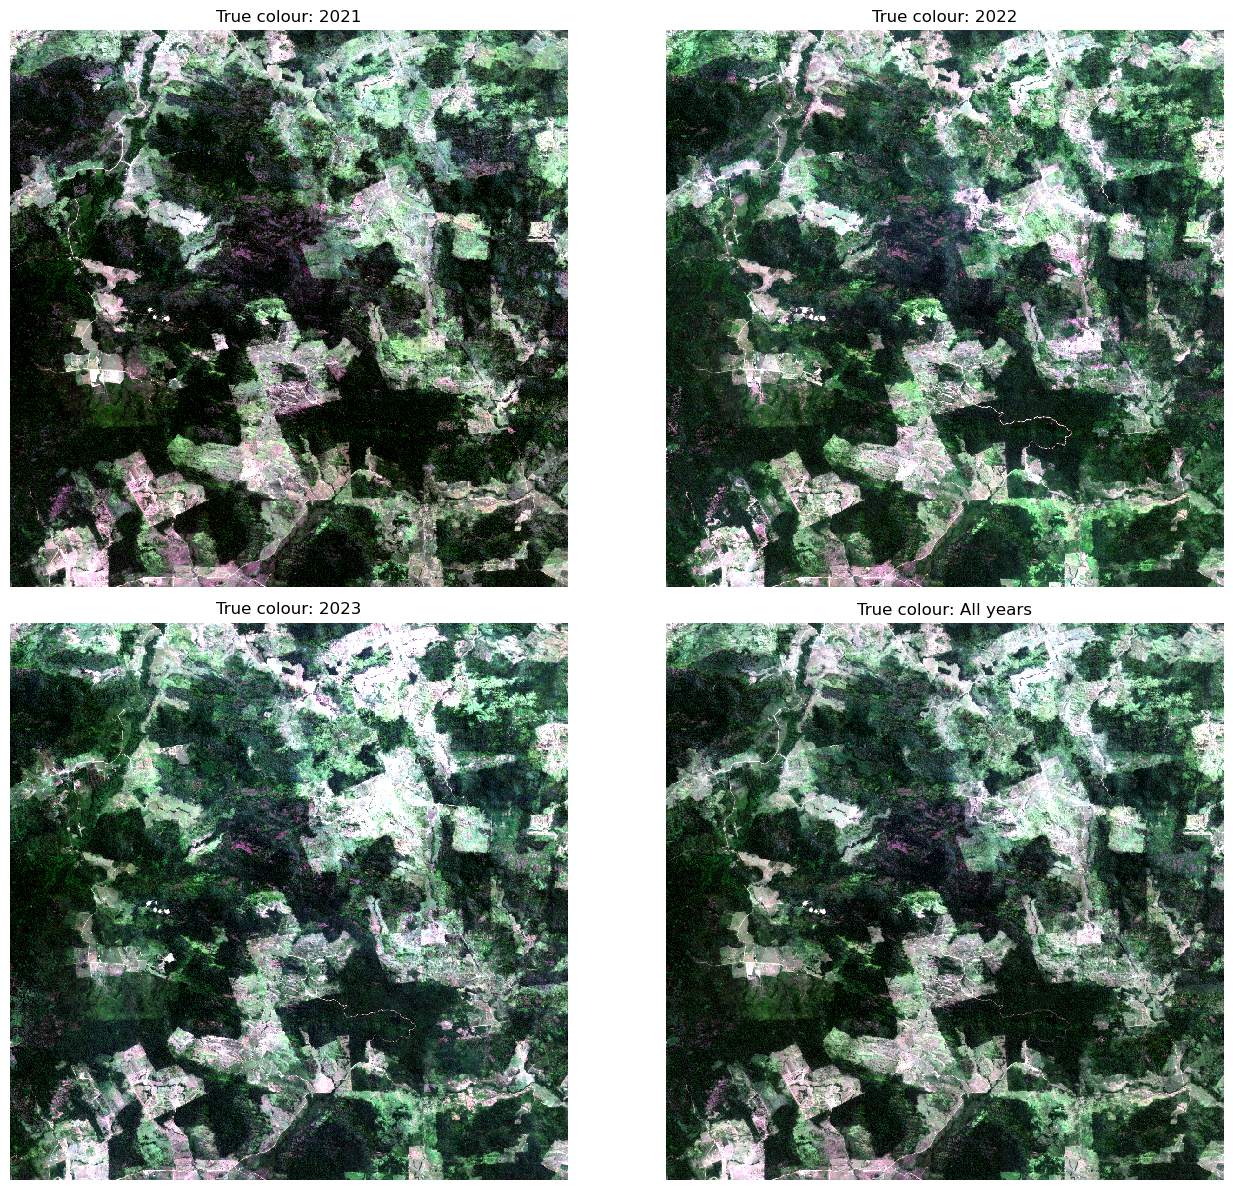

In [3]:
ref = composites["All years"]
limits = {}
for i in (0, 1, 2):
    values = ref[i][np.isfinite(ref[i])][::10]
    low, high = np.percentile(values, [2, 98])
    limits[i] = (low, high if high != low else low + 1e-6)


def to_rgb(arr):
    channels = []
    for i in (2, 1, 0):
        low, high = limits[i]
        scaled = np.clip((arr[i, ::DISPLAY_STEP, ::DISPLAY_STEP] - low) / (high - low), 0, 1)
        channels.append(np.nan_to_num(scaled))
    return np.dstack(channels)


fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, name in zip(axes.ravel(), FILES):
    if name in composites:
        ax.imshow(to_rgb(composites[name]), interpolation="nearest")
        ax.set_title(f"True colour: {name}")
    else:
        ax.set_title(f"{name}: missing")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3.4 NDVI
### 3.4.1 Calculate NDVI and its statistics
NDVI is a ratio, so it does not depend on whether reflectance is scaled. Pixels with `NIR + Red = 0` become **NaN**, never 0, so empty pixels are not mistaken for "no vegetation".
The table gives the number of valid pixels, mean, median and 5th/95th percentile per period (percentiles show the spread without being dominated by a few extremes) and is saved unrounded to `ndvi_statistics.csv`.
Values near 0.8-0.9 are typical of dense tropical forest, where NDVI saturates.

In [4]:
def ndvi_of(arr):
    red, nir = arr[2], arr[3]
    with np.errstate(divide="ignore", invalid="ignore"):
        return (nir - red) / (nir + red)


ndvis = {name: ndvi_of(arr) for name, arr in composites.items()}

statistics = []
for name, ndvi in ndvis.items():
    v = ndvi[np.isfinite(ndvi)]
    statistics.append({
        "period": name,
        "valid_pixels": len(v),
        "mean_ndvi": v.mean(),
        "median_ndvi": np.median(v),
        "p05_ndvi": np.percentile(v, 5),
        "p95_ndvi": np.percentile(v, 95),
    })

statistics_df = pd.DataFrame(statistics)
print(statistics_df.round(3).to_string(index=False))
statistics_df.to_csv(COMPOSITE_DIR / "ndvi_statistics.csv", index=False)

   period  valid_pixels  mean_ndvi  median_ndvi  p05_ndvi  p95_ndvi
     2021       5759440      0.810        0.837     0.633     0.910
     2022       5759440      0.806        0.844     0.616     0.897
     2023       5759440      0.807        0.845     0.609     0.904
All years       5759440      0.810        0.842     0.639     0.903


### 3.4.2 NDVI maps
Same colour scale for every panel (−0.2 to 1) so panels are comparable: below 0 is mostly water, cloud or shadow; above 0.8 is dense vegetation.
The change map is 2023 − 2021 (the longest span available) on a symmetric scale: white = no change, red = loss, blue = gain.

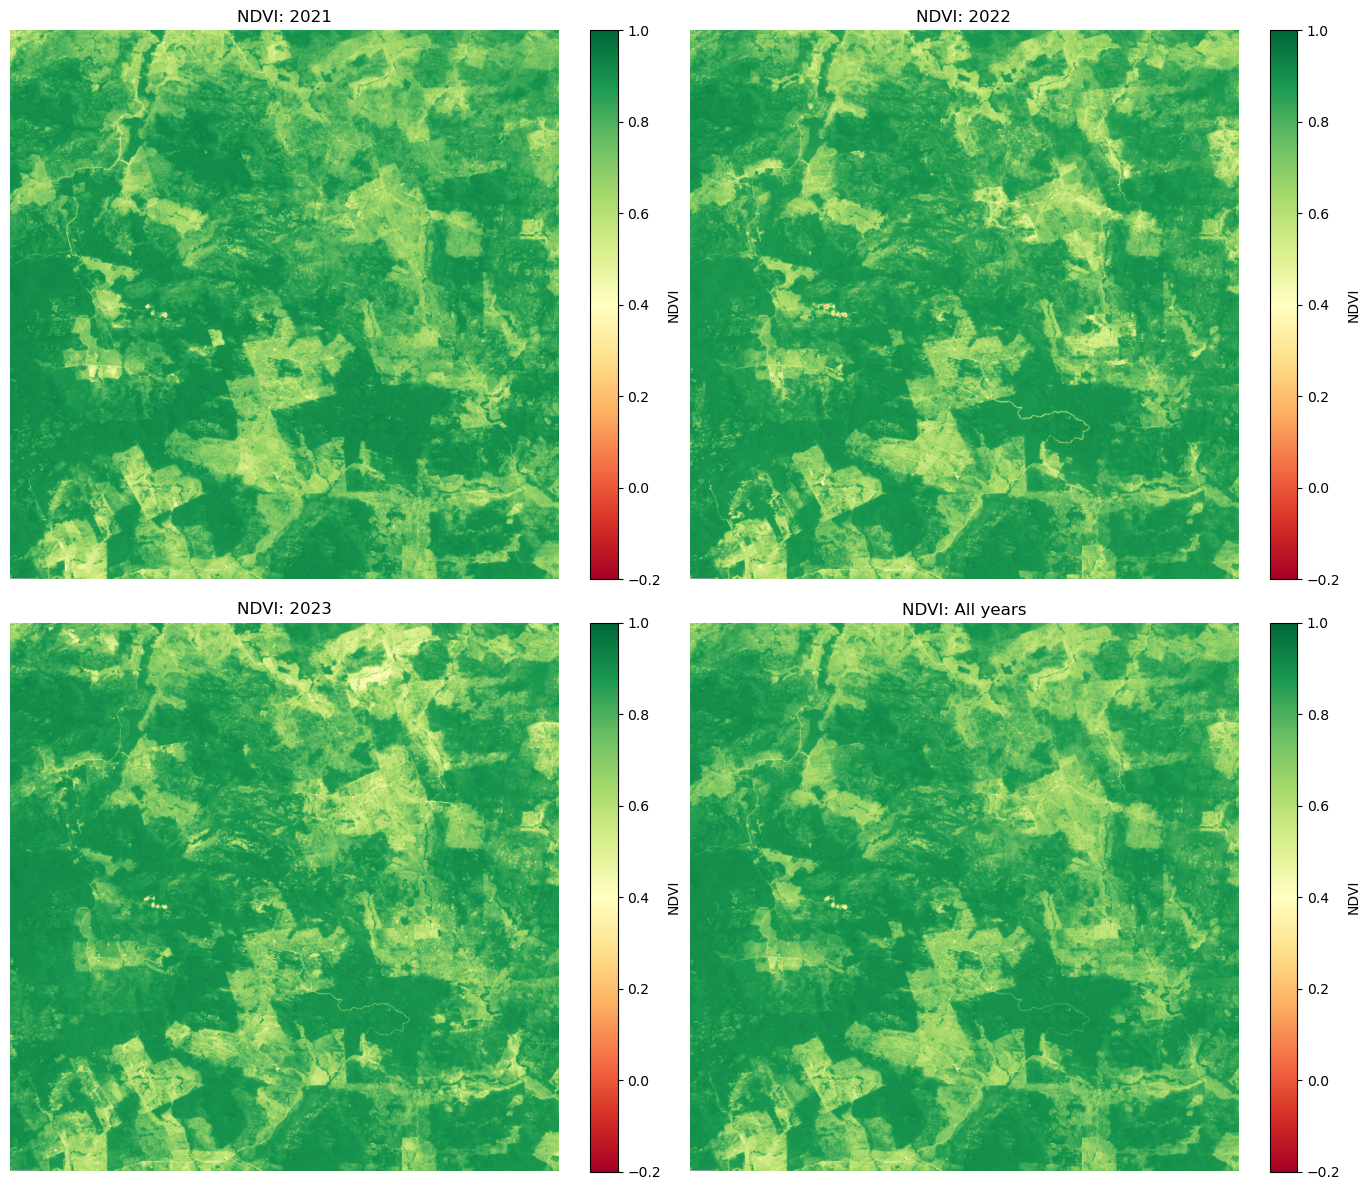

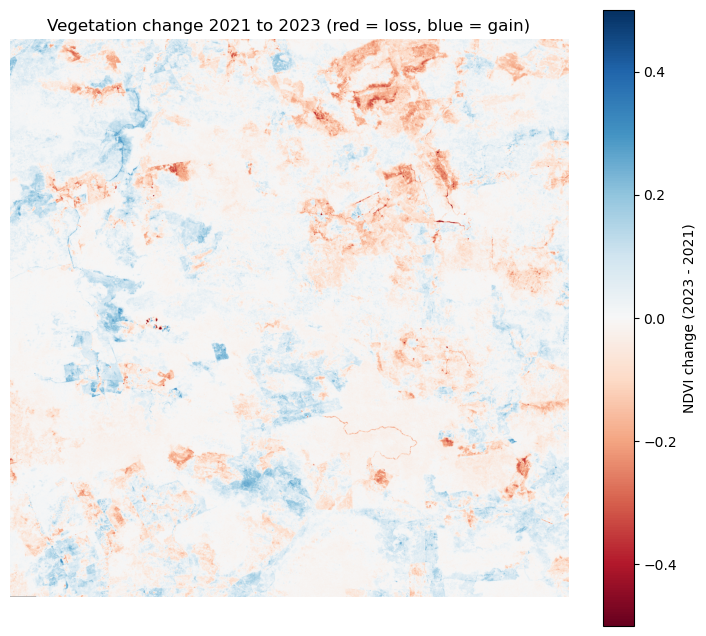

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, ndvi) in zip(axes.ravel(), ndvis.items()):
    im = ax.imshow(ndvi[::DISPLAY_STEP, ::DISPLAY_STEP], cmap="RdYlGn", vmin=-0.2, vmax=1)
    ax.set_title(f"NDVI: {name}")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, label="NDVI")
plt.tight_layout()
plt.show()

diff = ndvis["2023"] - ndvis["2021"]
plt.figure(figsize=(9, 8))
plt.imshow(diff[::DISPLAY_STEP, ::DISPLAY_STEP], cmap="RdBu", vmin=-0.5, vmax=0.5)
plt.colorbar(label="NDVI change (2023 - 2021)")
plt.title("Vegetation change 2021 to 2023 (red = loss, blue = gain)")
plt.axis("off")
plt.show()

## 3.5 NDVI change classes
### 3.5.1 Classify, count and measure
`change` = NDVI 2023 − NDVI 2021, only for pixels valid in **both** years (all others stay NaN). Negative = decline.
Pixels are split into five classes with two thresholds: **moderate ≥ 0.10** (above year-to-year noise) and **strong ≥ 0.20** (a clear drop, e.g. 0.85 → 0.65). The classes do not overlap and add up to the valid pixels.
Percentages use valid pixels as the denominator. Area uses the pixel size at the AOI's central latitude (a degree of longitude shrinks with the cosine of latitude), which is accurate to well under 1 % for an area this small.

In [6]:
MODERATE, STRONG = 0.10, 0.20

ndvi_2021, ndvi_2023 = ndvis["2021"], ndvis["2023"]
valid = np.isfinite(ndvi_2021) & np.isfinite(ndvi_2023)
change = np.full(valid.shape, np.nan, dtype="float32")
change[valid] = ndvi_2023[valid] - ndvi_2021[valid]

mid_lat = (bounds.top + bounds.bottom) / 2
pixel_ha = (pixel_size[0] * 111_320 * np.cos(np.radians(mid_lat))) * (pixel_size[1] * 110_574) / 10_000

classes = {
    f"Strong decrease (≤ -{STRONG:.2f})": change <= -STRONG,
    f"Moderate decrease (-{STRONG:.2f} to -{MODERATE:.2f})": (change <= -MODERATE) & (change > -STRONG),
    f"Little change (|Δ| < {MODERATE:.2f})": np.abs(change) < MODERATE,
    f"Moderate increase ({MODERATE:.2f} to {STRONG:.2f})": (change >= MODERATE) & (change < STRONG),
    f"Strong increase (≥ {STRONG:.2f})": change >= STRONG,
}

n_valid = int(valid.sum())
class_df = pd.DataFrame({
    "class": list(classes),
    "pixels": [int(m.sum()) for m in classes.values()],
})
class_df["% of valid"] = (class_df["pixels"] / n_valid * 100).round(2)
class_df["area_ha"] = (class_df["pixels"] * pixel_ha).round(1)

print(f"Valid pixels in both years: {n_valid:,} ({n_valid * pixel_ha / 100:,.0f} km²), pixel ≈ {pixel_ha * 10_000:.0f} m²")
print(class_df.to_string(index=False))
class_df.to_csv(COMPOSITE_DIR / "change_classes.csv", index=False)

Valid pixels in both years: 5,759,440 (568 km²), pixel ≈ 99 m²
                             class  pixels  % of valid  area_ha
         Strong decrease (≤ -0.20)   44290        0.77    436.5
Moderate decrease (-0.20 to -0.10)  263666        4.58   2598.5
        Little change (|Δ| < 0.10) 5209584       90.45  51341.2
  Moderate increase (0.10 to 0.20)  223035        3.87   2198.0
          Strong increase (≥ 0.20)   18865        0.33    185.9


### 3.5.2 Map the decline
Two binary maps: pixels with a decline of at least 0.10 (moderate **or** strong) and at least 0.20 (strong only).

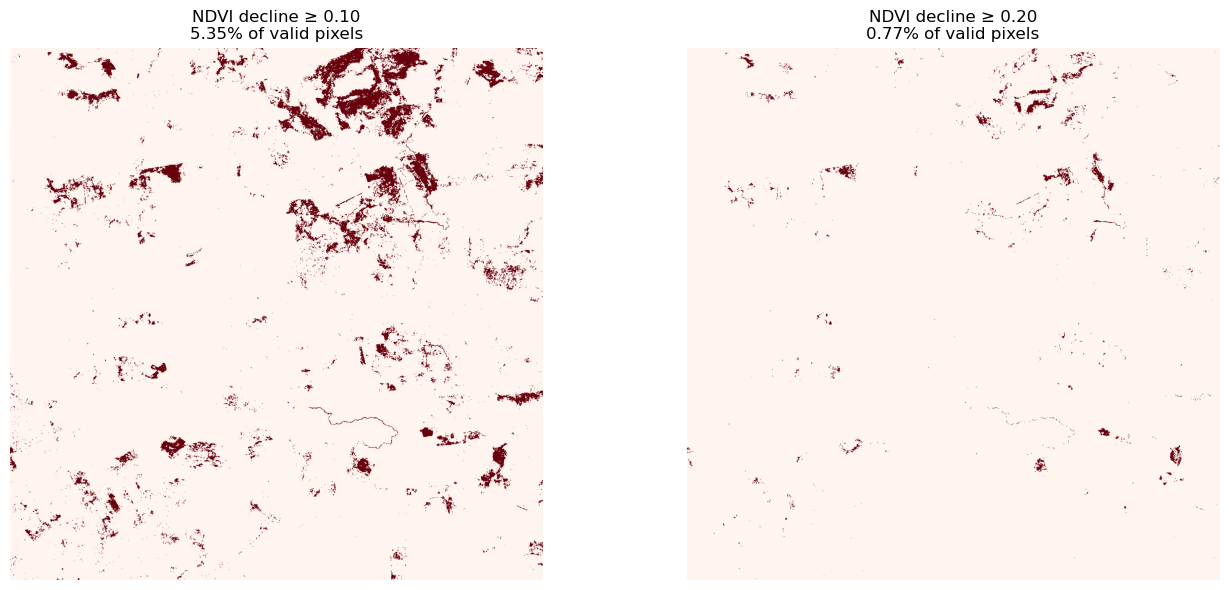

In [7]:
decline_010 = valid & (change <= -MODERATE)
decline_020 = valid & (change <= -STRONG)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, mask, threshold in ((axes[0], decline_010, MODERATE), (axes[1], decline_020, STRONG)):
    ax.imshow(mask[::DISPLAY_STEP, ::DISPLAY_STEP], cmap="Reds", vmin=0, vmax=1)
    ax.set_title(f"NDVI decline ≥ {threshold:.2f}\n{mask.sum() / n_valid:.2%} of valid pixels")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3.6 Decline patches
### 3.6.1 Find connected patches
The raw strong-decline mask contains isolated specks and 1-pixel gaps that are noise. A morphological **opening** (removes specks smaller than 3×3 px) followed by a **closing** (fills 1-px holes, so one clearing is not split) cleans it; the order matters, because closing first would join the specks.
`ndimage.label` then numbers each connected group of pixels (4-connectivity: pixels must share an edge; the Streamlit app counts diagonal neighbours too, so it reports slightly fewer patches).
Patches of at least **100 pixels (≈ 1 ha)** are kept as large patches, a common minimum for mapping forest loss. The table is saved to `decline_patches.csv`.

In [8]:
MIN_PIXELS = 100
kernel = np.ones((3, 3))

decline_clean = ndimage.binary_opening(decline_020, structure=kernel)
decline_clean = ndimage.binary_closing(decline_clean, structure=kernel)

labels, n_patches = ndimage.label(decline_clean)
patch_sizes = np.bincount(labels.ravel())[1:]
large_patch_ids = np.flatnonzero(patch_sizes >= MIN_PIXELS) + 1

print("Total decline patches:", n_patches)
print(f"Patches with at least {MIN_PIXELS} pixels:", len(large_patch_ids))
print("Largest patch size:", patch_sizes.max() if len(patch_sizes) else 0, "pixels")

centres = ndimage.center_of_mass(decline_clean, labels, large_patch_ids)
patch_df = pd.DataFrame({
    "patch_id": large_patch_ids,
    "pixels": patch_sizes[large_patch_ids - 1],
    "area_ha": (patch_sizes[large_patch_ids - 1] * pixel_ha).round(2),
    "center_lon": [bounds.left + (c + 0.5) * pixel_size[0] for _, c in centres],
    "center_lat": [bounds.top - (r + 0.5) * pixel_size[1] for r, _ in centres],
}).sort_values("pixels", ascending=False)

patch_df.to_csv(COMPOSITE_DIR / "decline_patches.csv", index=False)
display(patch_df.head(10).round(5))

Total decline patches: 311
Patches with at least 100 pixels: 55
Largest patch size: 2433 pixels


,patch_id,pixels,area_ha,center_lon,center_lat
20,96,2433,23.98,-52.34084,-6.68155
30,145,2173,21.42,-52.33266,-6.70976
28,140,1622,15.99,-52.31631,-6.70942
27,136,1485,14.63,-52.41896,-6.70804
13,70,1292,12.73,-52.34007,-6.67579
23,112,997,9.83,-52.36333,-6.68741
3,18,924,9.11,-52.45760,-6.66391
46,277,916,9.03,-52.28628,-6.82358
43,265,912,8.99,-52.31384,-6.81360
21,99,828,8.16,-52.34873,-6.68179


### 3.6.2 Outline the large patches
Each yellow rectangle is the **smallest rectangle containing one large patch** (`ndimage.find_objects`); the red area is the cleaned decline mask; the 10 largest patches are labelled with their ID and size in pixels (labelling all of them would hide the map).
A rectangle can contain pixels that are not part of the patch.

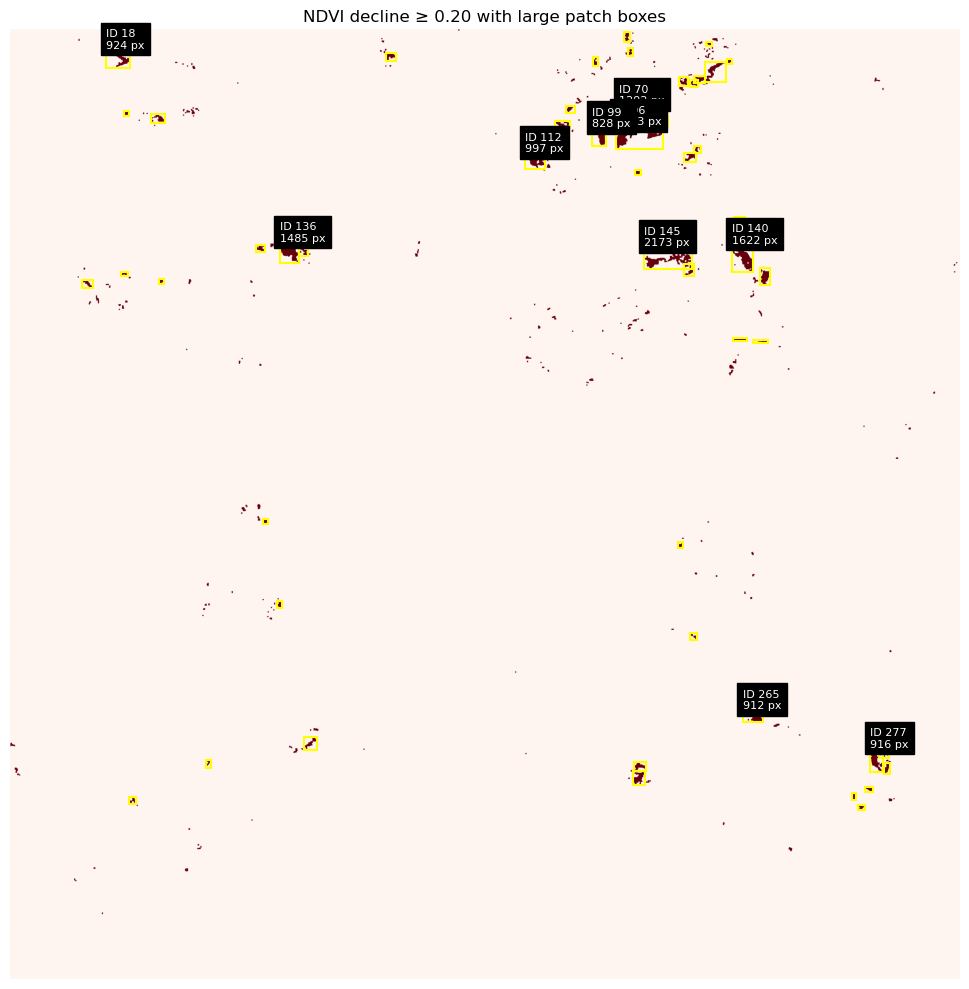

In [9]:
objects = ndimage.find_objects(labels)

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(decline_clean, cmap="Reds", vmin=0, vmax=1)

largest = set(large_patch_ids[np.argsort(patch_sizes[large_patch_ids - 1])[-10:]])

for patch_id in large_patch_ids:
    rows, cols = objects[patch_id - 1]
    ax.add_patch(Rectangle((cols.start, rows.start), cols.stop - cols.start, rows.stop - rows.start,
                           fill=False, edgecolor="yellow", linewidth=1.5))
    if patch_id in largest:
        ax.text(cols.start, rows.start, f"ID {patch_id}\n{patch_sizes[patch_id - 1]} px",
                color="white", fontsize=8, backgroundcolor="black")

ax.set_title("NDVI decline ≥ 0.20 with large patch boxes")
ax.axis("off")
plt.tight_layout()
plt.show()

## 3.7 Interpretation and limits
- NDVI change marks **areas to investigate, not confirmed deforestation**. A drop can also come from seasonality, clouds, fire, drought, flooding or harvest.
- The annual composites mix different acquisition dates and seasons; comparing images from the same months would be stronger evidence.
- The thresholds (0.10, 0.20) and the 1 ha minimum patch size are analyst choices; the reported area moves with them.
- Dense forest saturates NDVI near 0.8-0.9, so NDVI detects clearing better than degradation inside closed forest.
- Three annual points describe a change, not a statistical trend.

## 3.8 Future scope

With better data (denser, cloud-masked time series, matching seasons, rainfall and ground validation) this analysis could do much more:

- Compare images from the same months or seasons.
- Use monthly or quarterly time series instead of only annual composites.
- Add rainfall data.
- Add soil-moisture or soil-condition indicators.
- Add temperature and drought indicators.
- Add fire and burn-scar data.
- Add true-colour and false-colour composites.
- Add indices related to water, burn severity or vegetation stress.
- Add land-cover and protected-area layers.
- Compare results with official deforestation datasets (PRODES, DETER, MapBiomas).
- Add automated alerts for new change patches.
- Add confidence scores.
- Add field observations or validation points.
- Add cloud-probability and image-quality reporting.
- Add user-uploaded areas of interest.
- Add authenticated Planet API processing.
- Add scheduled data updates.
- Add historical time-series charts.
- Add automated PDF report generation on a schedule.
- Add a model to distinguish likely deforestation from seasonal or atmospheric effects.

*Each of these would require additional data, validation and processing time; none is implied by the current results.*